# Phase 2 – Unsupervised Learning
## CCO Retail Intelligence and Customer Retention Advisory System

This notebook groups customers into segments with two clustering algorithms and compares them. The segments will add context to the churn predictions from Phase 1 and support personalized retention advice.

| Part | Content |
|---|---|
| Part 1 | Algorithm 1: K-Means |
| Part 2 | Algorithm 2: Gaussian Mixture Model (GMM) |
| Part 3 | Comparison of the two algorithms |
| Part 4 | Integration strategy and limitations for the whole system |

Parts 1 and 2 each cover the clustering rationale, data preparation, cluster determination, evaluation and visualizations, and cluster interpretation for one algorithm. Part 2 also has its own integration and challenges sections. Part 3 compares the two algorithms. Part 4 gives the integration strategy and the challenges and limitations for the whole system.

The dataset is loaded and checked once below. Both algorithms start from the same data.

In [2]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# Look for the dataset in the usual project locations
CANDIDATES = ["../Dataset/retail_customer_churn.csv",
              "Dataset/retail_customer_churn.csv",
              "retail_customer_churn.csv"]
DATA_PATH = os.environ.get("CHURN_DATA") or next((p for p in CANDIDATES if os.path.exists(p)), CANDIDATES[0])
df = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH)
print("Shape:", df.shape)
df.head()

Loaded: ../Dataset/retail_customer_churn.csv
Shape: (100000, 18)


,customer_id,age_group,gender,region,customer_segment,preferred_channel,purchase_frequency,avg_order_value,total_spent,recency_days,website_visits,discount_usage_rate,email_open_rate,cart_abandonment_rate,loyalty_score,engagement_score,churn_risk,churn_flag
0,C000001,18-24,Other,North,Loyal,Online,5,381.27,2108.80,189,27,0.38,0.13,0.42,33,35.5,Medium,1
1,C000002,25-34,Other,South,New,Mobile App,12,376.65,3843.06,277,68,0.51,0.06,0.07,68,49.5,Medium,1
2,C000003,55+,Other,North,VIP,Online,5,37.73,224.65,271,23,0.64,0.22,0.46,73,38.0,High,1
3,C000004,18-24,Male,North,Returning,Mobile App,12,191.19,1960.79,89,93,0.66,0.31,0.13,93,59.0,Low,0
4,C000005,55+,Other,North,Returning,Mobile App,2,279.64,594.79,264,4,0.73,0.27,0.58,11,34.5,High,1


## Dataset Inspection (shared by both algorithms)

We checked the feature types, missing values, distributions, and correlations to understand the data before clustering.


In [3]:
ID_AND_TARGETS = ["customer_id", "churn_flag", "churn_risk"]   # exclude from clustering
num_cols = [c for c in df.select_dtypes(include="number").columns if c not in ID_AND_TARGETS]
cat_cols = [c for c in df.select_dtypes(exclude="number").columns if c not in ID_AND_TARGETS]
print("Numerical features  :", num_cols)
print("Categorical features:", cat_cols)
print("Missing values      :", int(df.isna().sum().sum()))
print("Duplicate rows      :", int(df.duplicated().sum()))

Numerical features  : ['purchase_frequency', 'avg_order_value', 'total_spent', 'recency_days', 'website_visits', 'discount_usage_rate', 'email_open_rate', 'cart_abandonment_rate', 'loyalty_score', 'engagement_score']
Categorical features: ['age_group', 'gender', 'region', 'customer_segment', 'preferred_channel']
Missing values      : 0
Duplicate rows      : 0


In [4]:
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
purchase_frequency,100000.0,11.80,14.37,1.00,2.00,8.00,12.00,60.00
avg_order_value,100000.0,209.70,109.71,20.03,114.61,209.48,304.75,400.00
total_spent,100000.0,2543.89,3790.84,17.87,381.32,1089.18,2952.17,28444.24
recency_days,100000.0,182.74,105.12,1.00,92.00,182.00,274.00,364.00
website_visits,100000.0,58.52,78.80,2.00,10.00,29.00,71.00,479.00
discount_usage_rate,100000.0,0.43,0.22,0.05,0.24,0.43,0.61,0.80
email_open_rate,100000.0,0.47,0.25,0.05,0.26,0.47,0.69,0.90
cart_abandonment_rate,100000.0,0.45,0.23,0.05,0.25,0.45,0.65,0.85
loyalty_score,100000.0,54.62,25.96,10.00,32.00,55.00,77.00,99.00
engagement_score,100000.0,51.18,16.83,10.00,39.00,51.00,63.00,92.00


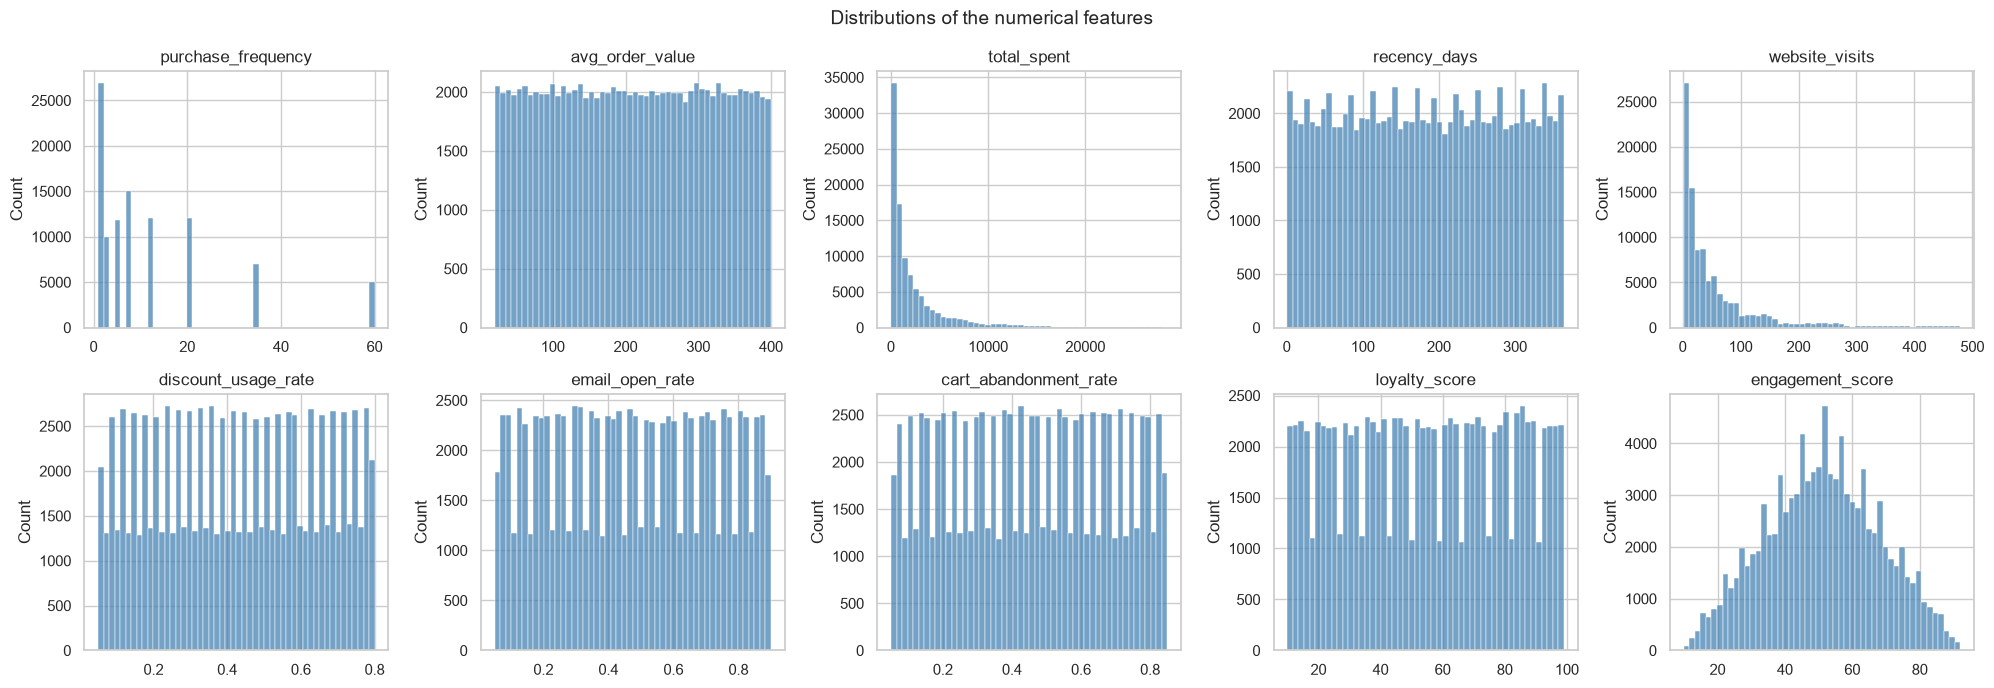

,n_unique,skewness
purchase_frequency,9,2.07
avg_order_value,35250,0.00
total_spent,86590,2.99
recency_days,364,-0.00
website_visits,478,2.59
discount_usage_rate,76,-0.00
email_open_rate,86,0.00
cart_abandonment_rate,81,-0.00
loyalty_score,90,-0.01
engagement_score,165,0.00


In [5]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], bins=50, ax=ax, color="steelblue")
    ax.set_title(c); ax.set_xlabel("")
plt.suptitle("Distributions of the numerical features", fontsize=14)
plt.tight_layout(); plt.show()

# Check unique values and skewness
pd.DataFrame({"n_unique": df[num_cols].nunique(), "skewness": df[num_cols].skew().round(2)})

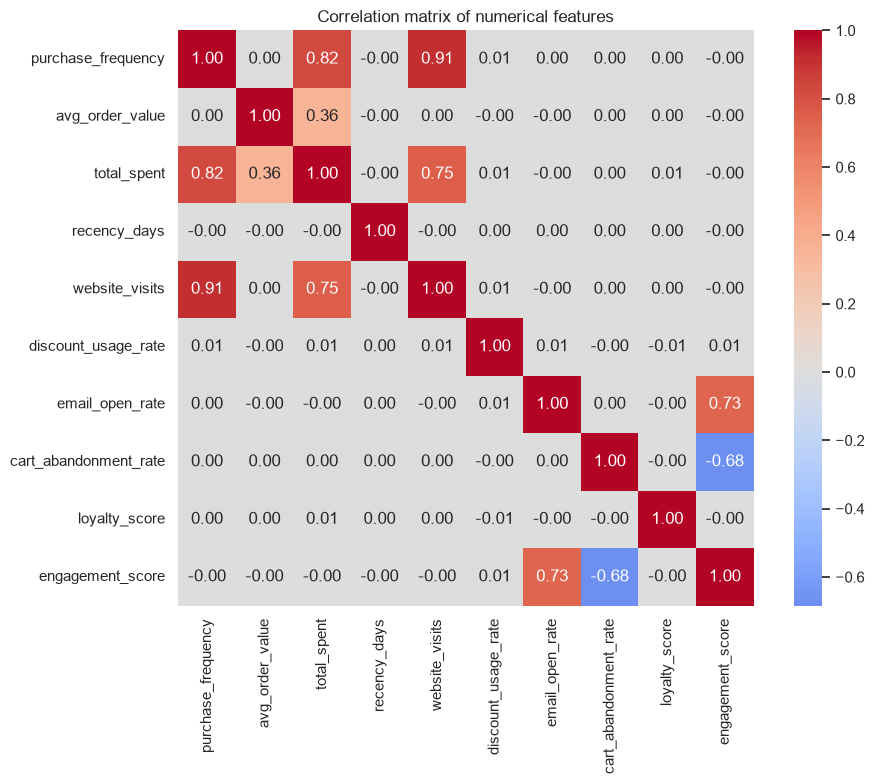

In [6]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix of numerical features")
plt.tight_layout(); plt.show()

# Part 1: Algorithm 1 – K-Means

## 1.1 Clustering Rationale & Algorithm Selection

We chose K-Means for four reasons.

- **Dataset size:** we have 100,000 customers. K-Means scales well to this size.
- **Feature types:** most of our features are numeric behavior measures (purchases, visits, email opens, engagement). After scaling, distance-based clustering works well on them. The five categorical features are one-hot encoded.
- **Interpretability:** each cluster has a center, so every segment can be described as an average customer profile. This is easy to explain to business users.
- **Baseline value:** it is a standard, simple method. We compare it with the Gaussian Mixture Model in Part 3.

K-Means has limits. It assumes clusters are compact and roughly spherical. We must choose the number of clusters ourselves. It is also sensitive to feature scale and to skewed values, so we check the skewness of our features before clustering.

## 1.2 Data Preparation (target removal, feature scaling)

We prepare the data in four steps.

1. **Remove columns that must not be used.** `customer_id` is only an identifier. `churn_flag` is the class label, so it is removed before clustering. We keep it aside to describe the clusters afterwards. `churn_risk` is also removed because it is built from the target (High always means churned and Low always means retained). This leaves 15 features: 10 numeric and 5 categorical.
2. **Check skewness** of the numeric features (done in the dataset inspection above).
3. **Log-transform the skewed features.**
4. **Scale and encode.** Numeric features are standardized and categorical features are one-hot encoded.

Part 2 prepares its data differently: it uses only the 10 numeric features and no log transform. We compare the effect of this in Part 3.

In [7]:
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

results_dir = Path("clustering_results")   
results_dir.mkdir(exist_ok=True)

y_churn = df["churn_flag"].copy()

X_km_raw = df.drop(columns=ID_AND_TARGETS)

print("K-Means feature matrix:", X_km_raw.shape)
print("Numerical features:", num_cols)
print("Categorical features:", cat_cols)
print("Missing values:", int(X_km_raw.isnull().sum().sum()))

K-Means feature matrix: (100000, 15)
Numerical features: ['purchase_frequency', 'avg_order_value', 'total_spent', 'recency_days', 'website_visits', 'discount_usage_rate', 'email_open_rate', 'cart_abandonment_rate', 'loyalty_score', 'engagement_score']
Categorical features: ['age_group', 'gender', 'region', 'customer_segment', 'preferred_channel']
Missing values: 0


### 1.2.1 Why we transform some features

Three features are strongly right-skewed (skewness above 2): `purchase_frequency`, `total_spent` and `website_visits`. They are also highly correlated with each other (0.75 to 0.91). K-Means uses distance, so a small group of very high-volume customers can dominate the result.

In an earlier attempt without a transform, K-Means with k = 2 mostly split off a small group of high-volume customers (about 12% of customers) from everyone else. To avoid this, we apply log(1 + x) to these three features before scaling. The other numeric features are symmetric and stay unchanged.

In [8]:
skewed_features = ["purchase_frequency", "total_spent", "website_visits"]
X_km_model = X_km_raw.copy()
X_km_model[skewed_features] = np.log1p(X_km_model[skewed_features])

# Standardize numeric features and one-hot encode categorical features
km_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ]
)

X_km = km_preprocessor.fit_transform(X_km_model)
km_feature_names = km_preprocessor.get_feature_names_out()

print("Original feature shape:", X_km_raw.shape)
print("Processed feature shape:", X_km.shape)

Original feature shape: (100000, 15)
Processed feature shape: (100000, 30)


## 1.3 Cluster Determination & Implementation

### 1.3.1 Choosing the number of clusters

We tried k from 2 to 8 on a random sample of 10,000 customers. For each k we recorded three measures: inertia (WCSS), the Silhouette Score, and the Davies-Bouldin Index. We also report the churn-rate range across clusters. This is only a business-relevance check. Churn is not used to form the clusters.

In [9]:
km_sample_idx = np.random.RandomState(RANDOM_STATE).choice(X_km.shape[0], size=10000, replace=False)
X_km_sample = X_km[km_sample_idx]
churn_sample = y_churn.to_numpy()[km_sample_idx]

t0 = time.time()
km_rows = []
for k in range(2, 9):
    km_k = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_km_sample)
    labels_k = km_k.labels_
    churn_by_cluster = pd.Series(churn_sample).groupby(labels_k).mean() * 100
    km_rows.append({
        "k": k,
        "inertia (WCSS)": round(km_k.inertia_),
        "silhouette": round(silhouette_score(X_km_sample, labels_k, sample_size=3000, random_state=RANDOM_STATE), 3),
        "davies_bouldin": round(davies_bouldin_score(X_km_sample, labels_k), 2),
        "churn range (pct points)": round(churn_by_cluster.max() - churn_by_cluster.min(), 1),
    })
km_search_seconds = time.time() - t0

km_results = pd.DataFrame(km_rows)
print(f"K-Means search took {km_search_seconds:.0f}s")
km_results

K-Means search took 4s


,k,inertia (WCSS),silhouette,davies_bouldin,churn range (pct points)
0,2,117415,0.122,2.44,5.5
1,3,109179,0.096,2.46,14.5
2,4,103959,0.078,2.75,17.4
3,5,100768,0.077,2.56,25.4
4,6,97815,0.076,2.51,25.2
5,7,95510,0.072,2.61,25.6
6,8,93502,0.068,2.59,27.9


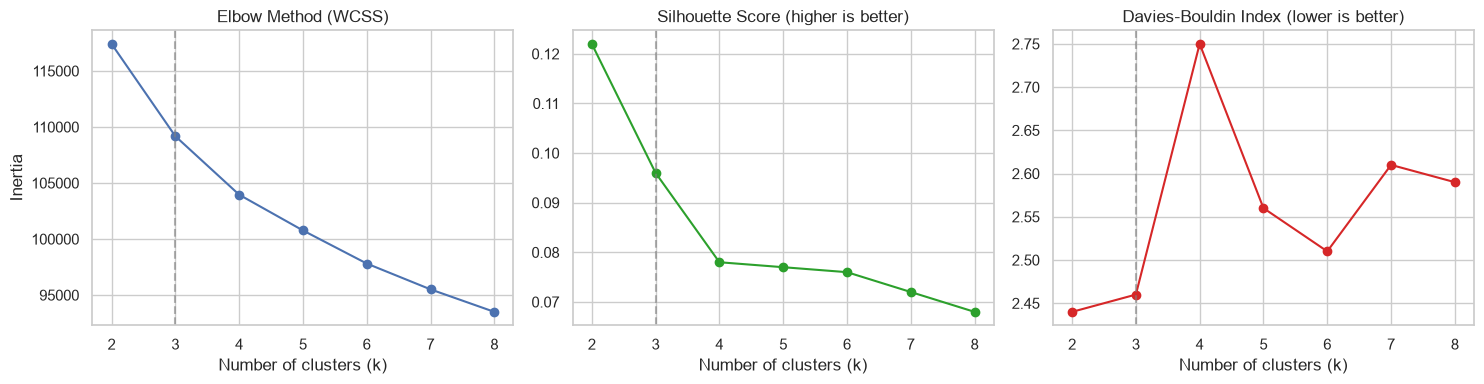

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(km_results["k"], km_results["inertia (WCSS)"], marker="o")
axes[0].set(title="Elbow Method (WCSS)", xlabel="Number of clusters (k)", ylabel="Inertia")

axes[1].plot(km_results["k"], km_results["silhouette"], marker="o", color="tab:green")
axes[1].set(title="Silhouette Score (higher is better)", xlabel="Number of clusters (k)")

axes[2].plot(km_results["k"], km_results["davies_bouldin"], marker="o", color="tab:red")
axes[2].set(title="Davies-Bouldin Index (lower is better)", xlabel="Number of clusters (k)")

for ax in axes:
    ax.axvline(3, linestyle="--", color="gray", alpha=0.6)

plt.tight_layout()
plt.savefig(results_dir / "k_selection.png", dpi=150)
plt.show()

### 1.3.2 Choosing k = 3

No value of k stands out clearly.

- **WCSS:** the curve falls smoothly. There is only a mild bend around k = 3 and k = 4, not a sharp elbow.
- **Silhouette:** it is highest at k = 2 (0.122), then drops to 0.096 at k = 3 and 0.078 at k = 4. All values are low, so the segments overlap.
- **Davies-Bouldin:** k = 2 and k = 3 are the best (2.44 and 2.46). It gets worse at k = 4 (2.75).

We chose **k = 3**. It is almost as good as k = 2 on the Davies-Bouldin Index, and better than every higher k on both internal measures. It also gives three balanced segments that are easy to describe. With k = 2 the churn rates of the two clusters differ by only about 5.5 percentage points. With k = 3 they differ by about 14.5 points (on this sample). A higher k gives a larger churn range, but it lowers the silhouette score and creates more segments than a business team can act on.

Because no k is clearly optimal, we treat k = 3 as a reasonable and explainable choice. We state this again in the limitations.

In [11]:
K_KM = 3
t0 = time.time()
km_model = KMeans(n_clusters=K_KM, random_state=RANDOM_STATE, n_init=10).fit(X_km)
km_fit_seconds = time.time() - t0
km_raw_labels = km_model.labels_

km_raw_profile = df.assign(raw=km_raw_labels).groupby("raw")[["purchase_frequency", "engagement_score"]].mean()
volume_cluster = km_raw_profile["purchase_frequency"].idxmax()
low_engagement_cluster = km_raw_profile.drop(volume_cluster)["engagement_score"].idxmin()
engaged_cluster = [c for c in km_raw_profile.index if c not in (volume_cluster, low_engagement_cluster)][0]

km_order = {int(volume_cluster): 0, int(low_engagement_cluster): 1, int(engaged_cluster): 2}
KM_SEGMENTS = {0: "High-Volume Buyers", 1: "Low-Engagement Customers", 2: "Engaged Light Buyers"}
KM_COLORS = {"High-Volume Buyers": "tab:blue", "Low-Engagement Customers": "tab:red", "Engaged Light Buyers": "tab:green"}

km_labels = pd.Series(km_raw_labels).map(km_order).to_numpy()
df["kmeans_cluster"] = km_labels
df["kmeans_segment"] = df["kmeans_cluster"].map(KM_SEGMENTS)

km_sizes = df["kmeans_segment"].value_counts().reindex(KM_SEGMENTS.values())
display(pd.DataFrame({"customers": km_sizes, "share (%)": (km_sizes / len(df) * 100).round(1)}))

,customers,share (%)
kmeans_segment,,
High-Volume Buyers,37796,37.8
Low-Engagement Customers,31485,31.5
Engaged Light Buyers,30719,30.7


## 1.4 Evaluation Metrics & Visualizations

We evaluate the final model with three internal measures: the Silhouette Score, the Davies-Bouldin Index and WCSS. We also check how stable the result is across random starts.

BCubed precision and recall are optional and need ground-truth groups. We do not have true customer segments, and `churn_flag` is not a segment label, so we do not use them.

In [12]:
km_silhouette = silhouette_score(X_km, km_labels, sample_size=10000, random_state=RANDOM_STATE)
km_db = davies_bouldin_score(X_km, km_labels)
km_wcss = km_model.inertia_

print(f"Silhouette Score:     {km_silhouette:.3f}")
print(f"Davies-Bouldin Index: {km_db:.3f}")
print(f"WCSS (inertia):       {km_wcss:,.0f}")

km_seed_labels = [KMeans(n_clusters=K_KM, random_state=s, n_init=10).fit_predict(X_km_sample) for s in range(5)]
km_ari = [adjusted_rand_score(km_seed_labels[0], other) for other in km_seed_labels[1:]]
print("Agreement between runs (Adjusted Rand Index):", [round(a, 3) for a in km_ari])

Silhouette Score:     0.099
Davies-Bouldin Index: 2.448
WCSS (inertia):       1,091,475
Agreement between runs (Adjusted Rand Index): [0.996, 1.0, 0.999, 0.999]


### 1.4.1 Evaluation Results

| Measure | Value |
|---|---|
| Silhouette Score | 0.099 |
| Davies-Bouldin Index | 2.448 |
| WCSS (inertia) | 1,091,475 |

The silhouette score is close to zero, so the segments are not sharply separated and overlap at the edges. The result is stable: five runs with different random seeds agree almost perfectly (Adjusted Rand Index of 0.996 or higher). The segments are a consistent way to divide the customers, but they are broad groups and not natural, well-separated clusters.

WCSS has no direct good or bad value. We use it to compare different values of k, as in the table above.

### 1.4.2 Visualizations

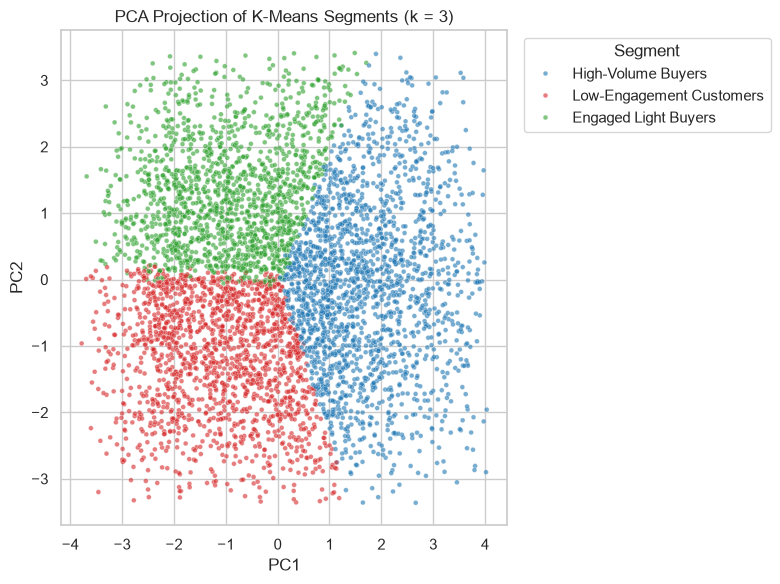

Variance explained by the two components: 34.99 %

Top features for PC1:
num__purchase_frequency    0.57
num__total_spent           0.57
num__website_visits        0.56
num__avg_order_value       0.16
num__recency_days         -0.00

Top features for PC2:
num__engagement_score         0.71
num__email_open_rate          0.52
num__cart_abandonment_rate   -0.48
num__discount_usage_rate      0.01
num__avg_order_value         -0.01


In [13]:
km_pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_km_pca = km_pca.fit_transform(X_km)

km_plot_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_km_pca), size=5000, replace=False)
km_plot_df = pd.DataFrame({
    "PC1": X_km_pca[km_plot_idx, 0],
    "PC2": X_km_pca[km_plot_idx, 1],
    "Segment": df["kmeans_segment"].to_numpy()[km_plot_idx],
})

plt.figure(figsize=(8, 6))
sns.scatterplot(data=km_plot_df, x="PC1", y="PC2", hue="Segment",
                hue_order=list(KM_SEGMENTS.values()), palette=KM_COLORS, s=12, alpha=0.6)
plt.legend(title="Segment", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.title("PCA Projection of K-Means Segments (k = 3)")
plt.tight_layout()
plt.savefig(results_dir / "pca_clusters.png", dpi=150)
plt.show()

print("Variance explained by the two components:", round(km_pca.explained_variance_ratio_.sum() * 100, 2), "%")

km_loadings = pd.DataFrame(km_pca.components_.T, index=km_feature_names, columns=["PC1", "PC2"])
for pc in ["PC1", "PC2"]:
    top = km_loadings[pc].reindex(km_loadings[pc].abs().sort_values(ascending=False).index).head(5)
    print(f"\nTop features for {pc}:")
    print(top.round(2).to_string())

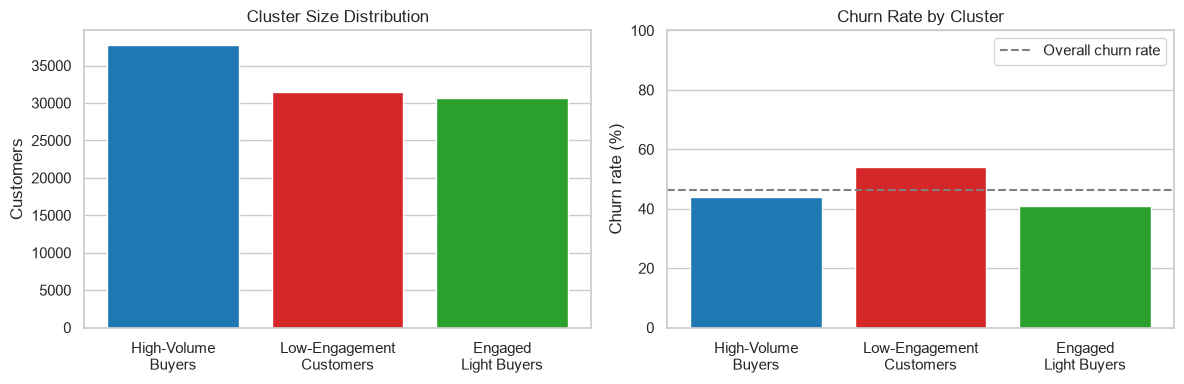

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
seg_labels_wrapped = [n.replace(" ", "\n", 1) for n in KM_SEGMENTS.values()]

axes[0].bar(range(K_KM), km_sizes.values, color=list(KM_COLORS.values()))
axes[0].set_xticks(range(K_KM)); axes[0].set_xticklabels(seg_labels_wrapped)
axes[0].set(title="Cluster Size Distribution", ylabel="Customers")

km_churn_by_segment = df.groupby("kmeans_segment")["churn_flag"].mean().reindex(KM_SEGMENTS.values()) * 100
axes[1].bar(range(K_KM), km_churn_by_segment.values, color=list(KM_COLORS.values()))
axes[1].axhline(y_churn.mean() * 100, linestyle="--", color="gray", label="Overall churn rate")
axes[1].set_xticks(range(K_KM)); axes[1].set_xticklabels(seg_labels_wrapped)
axes[1].set(title="Churn Rate by Cluster", ylabel="Churn rate (%)", ylim=(0, 100))
axes[1].legend()
for ax in axes:
    ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.savefig(results_dir / "cluster_size_and_churn.png", dpi=150)
plt.show()

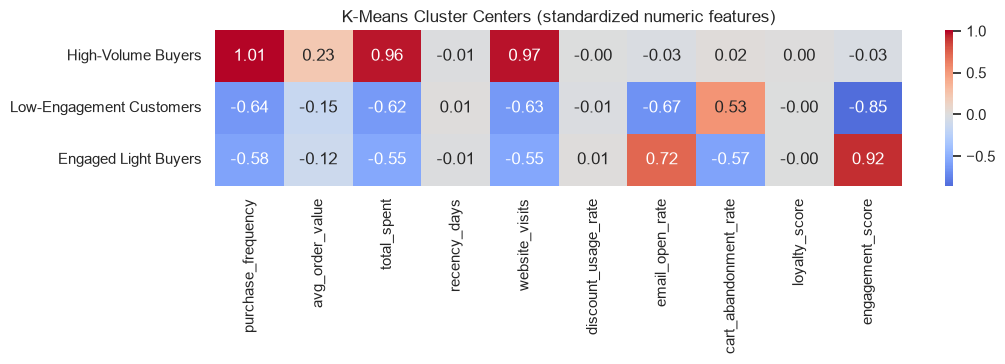

,separation between clusters
engagement_score,1.77
purchase_frequency,1.65
website_visits,1.60
total_spent,1.58
email_open_rate,1.40
cart_abandonment_rate,1.10
avg_order_value,0.38
discount_usage_rate,0.03
recency_days,0.02
loyalty_score,0.01


In [15]:
km_centers = pd.DataFrame(km_model.cluster_centers_, columns=km_feature_names)
km_numeric_cols = [c for c in km_feature_names if c.startswith("num__")]
km_centers_num = km_centers[km_numeric_cols].loc[[volume_cluster, low_engagement_cluster, engaged_cluster]]
km_centers_num.index = list(KM_SEGMENTS.values())
km_centers_num.columns = [c.replace("num__", "") for c in km_numeric_cols]

plt.figure(figsize=(11, 3.8))
sns.heatmap(km_centers_num, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("K-Means Cluster Centers (standardized numeric features)")
plt.tight_layout()
plt.savefig(results_dir / "cluster_feature_heatmap.png", dpi=150)
plt.show()

# Features that separate the clusters most (gap between highest and lowest cluster center)
km_separation = (km_centers_num.max() - km_centers_num.min()).sort_values(ascending=False).round(2)
display(km_separation.to_frame("separation between clusters"))

### 1.4.3 What the plots show

- **PCA plot:** the two components explain about 35% of the variance, so this is a partial view. PC1 is driven by purchase volume (`purchase_frequency`, `total_spent`, `website_visits`). PC2 is driven by engagement (`engagement_score`, `email_open_rate`, `cart_abandonment_rate`). The segments touch each other with no empty gap between them. This fits the low silhouette score: the customers form a continuous cloud, and K-Means divides it into three regions.
- **Cluster sizes:** the segments are well balanced (37.8%, 31.5% and 30.7%).
- **Churn rate:** the Low-Engagement segment churns the most (54.1%). The other two are below the overall rate of 46.2%.
- **Cluster centers:** purchase volume and engagement separate the clusters. Recency, loyalty score and discount usage are almost identical across clusters.

## 1.5 Cluster Interpretation & Profiles

The tables below show the average profile of each segment in the original units, the churn rate of each segment, and whether the categorical features differ between segments.

In [16]:
km_profile = df.groupby("kmeans_segment")[num_cols].mean().reindex(KM_SEGMENTS.values()).round(2)
display(km_profile.T)

km_churn_profile = df.groupby("kmeans_segment")["churn_flag"].agg(
    customers="count", churned="sum", churn_rate="mean"
).reindex(KM_SEGMENTS.values())
km_churn_profile["churn_rate"] = (km_churn_profile["churn_rate"] * 100).round(2)
display(km_churn_profile)
print("Overall churn rate:", round(y_churn.mean() * 100, 2), "%")

km_gaps = []
for col in cat_cols:
    table = pd.crosstab(df["kmeans_segment"], df[col], normalize="index") * 100
    km_gaps.append({"feature": col, "largest gap between segments (pct points)": round((table.max() - table.min()).max(), 2)})
display(pd.DataFrame(km_gaps))

kmeans_segment,High-Volume Buyers,Low-Engagement Customers,Engaged Light Buyers
purchase_frequency,24.36,3.98,4.38
avg_order_value,234.65,192.88,196.26
total_spent,5527.68,688.48,774.38
recency_days,182.03,184.26,182.05
website_visits,122.97,18.38,20.37
discount_usage_rate,0.43,0.42,0.43
email_open_rate,0.47,0.31,0.65
cart_abandonment_rate,0.46,0.57,0.32
loyalty_score,54.72,54.50,54.60
engagement_score,50.61,36.78,66.63


,customers,churned,churn_rate
kmeans_segment,,,
High-Volume Buyers,37796,16637,44.02
Low-Engagement Customers,31485,17036,54.11
Engaged Light Buyers,30719,12551,40.86


Overall churn rate: 46.22 %


,feature,largest gap between segments (pct points)
0,age_group,0.79
1,gender,1.22
2,region,0.99
3,customer_segment,0.37
4,preferred_channel,0.53


### 1.5.1 Segment Profiles

**High-Volume Buyers (37.8% of customers, churn rate 44.0%).** They buy often (about 24 purchases on average), spend the most (about 5,528 in total) and visit the website the most (about 123 visits). Their engagement score and email open rate are close to the average.

**Low-Engagement Customers (31.5%, churn rate 54.1%).** They make few purchases (about 4) and spend little (about 688). They have the lowest email open rate (0.31), the highest cart abandonment (0.57) and the lowest engagement score (36.8). This is the highest-risk segment.

**Engaged Light Buyers (30.7%, churn rate 40.9%).** They also buy rarely (about 4 purchases, about 774 in total), but they open the most emails (0.65), abandon the fewest carts (0.32) and have the highest engagement score (66.6). This is the lowest-risk segment.

### 1.5.2 What the segments do not capture

Recency, loyalty score, discount usage and all five categorical features (age group, gender, region, customer segment, preferred channel) are almost the same in every segment. The largest gap in any categorical feature is only about 1.2 percentage points. So the segments reflect **how much** customers buy and **how engaged** they are, not who they are.

`recency_days` is the strongest churn signal in our data (r = 0.77 in Part A), yet it does not separate these segments. The segments therefore explain churn only partly. The gap in churn rates (40.9% to 54.1%) is real but modest.

### 1.5.3 What this means for the advice system

These are suggested actions. They should be tested before use.

- **High-Volume Buyers:** they are valuable, and 44% of them still churn. Protect them with loyalty rewards or early access to offers.
- **Low-Engagement Customers:** this is the first priority. Re-engagement emails and cart-abandonment reminders match their behavior.
- **Engaged Light Buyers:** they respond to communication but spend little. Product recommendations and offers could increase their order size.

## 1.6 Saving and Reusing the K-Means Model

As for the GMM in Part 2, we save the fitted preparation steps and the K-Means model. New customers can then be assigned to the same segments without retraining.

In [17]:
import joblib
os.makedirs("outputs", exist_ok=True)

# Everything needed to assign new customers to the same K-Means segments
km_bundle = {
    "preprocessor": km_preprocessor,       # fitted scaler + one-hot encoder
    "kmeans": km_model,                    # fitted K-Means model
    "order": km_order,                     # raw K-Means cluster id -> ordered cluster number
    "segments": KM_SEGMENTS,               # cluster number -> segment name
    "skewed_features": skewed_features,    # columns that get log(1 + x)
    "features": list(X_km_raw.columns),    # input columns in the correct order
}
joblib.dump(km_bundle, "outputs/kmeans_model.joblib")
print("Saved -> outputs/kmeans_model.joblib")

# Load the saved model and use it to assign segments
km_loaded = joblib.load("outputs/kmeans_model.joblib")

def assign_kmeans_segment(customers):
    data = customers[km_loaded["features"]].copy()
    data[km_loaded["skewed_features"]] = np.log1p(data[km_loaded["skewed_features"]])
    raw = km_loaded["kmeans"].predict(km_loaded["preprocessor"].transform(data))
    clusters = pd.Series(raw, index=customers.index).map(km_loaded["order"])
    return pd.DataFrame({"kmeans_cluster": clusters, "kmeans_segment": clusters.map(km_loaded["segments"])})

# Check that the saved model reproduces the existing assignments
check_km = assign_kmeans_segment(df)
print("Same segments as before:", (check_km["kmeans_cluster"].values == df["kmeans_cluster"].values).all())

# Example of a new customer
new_customer_km = pd.DataFrame([{
    "age_group": "25-34", "gender": "Female", "region": "North",
    "customer_segment": "Loyal", "preferred_channel": "Online",
    "purchase_frequency": 3, "avg_order_value": 200, "total_spent": 600,
    "recency_days": 200, "website_visits": 15, "discount_usage_rate": 0.4,
    "email_open_rate": 0.2, "cart_abandonment_rate": 0.6,
    "loyalty_score": 50, "engagement_score": 35,
}])
display(assign_kmeans_segment(new_customer_km))

Saved -> outputs/kmeans_model.joblib
Same segments as before: True


,kmeans_cluster,kmeans_segment
0,1,Low-Engagement Customers


The saved model gives every existing customer the same segment as before. New customers can therefore be assigned to a segment in the same way. As with the GMM, this assigns a segment only. It does not predict churn.

# Part 2: Algorithm 2 – Gaussian Mixture Model (GMM)

This part applies Gaussian Mixture Model (GMM) to group customers based on their purchasing and engagement behavior. GMM is our second clustering algorithm alongside K-Means.

We prepare the data, choose the number of clusters, evaluate GMM, describe the customer groups, and discuss how the results could support the CCO system.

## 2.1 Clustering Rationale & Algorithm Selection

### 2.1.1 Algorithm Selection and Justification

We selected GMM as our second clustering algorithm to compare with K-Means. Our dataset contains 100,000 customers, with 10 numerical and 5 categorical features after excluding the ID and churn-related columns.

The plots show that purchase frequency, total spending, and website visits are right-skewed. Some purchasing features are strongly correlated; for example, purchase frequency and website visits have a correlation of 0.91.

GMM provides probabilities of belonging to each cluster. With full covariance, it can also account for relationships between numerical features within each group. This makes it useful for comparison with K-Means, which assigns each customer to one cluster based on distance.

We also considered K-Prototypes because the dataset has categorical features, and DBSCAN because it can find clusters with different shapes. However, K-Prototypes requires choices about how to balance categorical and numerical features, while DBSCAN requires suitable density parameters.

GMM has limitations. Some of our features are skewed or discrete, and the results may depend on how the model is initialized. We evaluate the results before deciding whether the clusters are meaningful.


## 2.2 Data Preparation

We excluded `customer_id`, `churn_flag`, and `churn_risk` from the clustering inputs. We used the 10 numerical features and applied `StandardScaler` because the feature ranges are very different.

The dataset has no missing values, so imputation was not needed. We excluded categorical features from the main GMM model because they are not directly suited to Gaussian modeling.

In [18]:
from sklearn.pipeline import Pipeline

FEATURES = num_cols
preprocess = Pipeline([
    ("scale", StandardScaler()),
])
X = preprocess.fit_transform(df[FEATURES])
print("Clustering matrix:", X.shape)
print("Means ≈ 0:", np.allclose(X.mean(0), 0, atol=1e-8), "| Std ≈ 1:", np.allclose(X.std(0), 1, atol=1e-8))

Clustering matrix: (100000, 10)
Means ≈ 0: True | Std ≈ 1: True


### 2.2.1 Categorical Feature Selection

We used numerical features for GMM because one-hot encoded categorical values do not fit its Gaussian assumptions as naturally. We also checked whether average purchasing and engagement behavior differed much across the categorical groups.


In [19]:
# Compare average customer activity across categories
check = []
for c in cat_cols:
    g = df.groupby(c)[["purchase_frequency", "total_spent", "loyalty_score", "engagement_score"]].mean()
    check.append((g.max() - g.min()).rename(c))
print("Range of category means (max - min) per feature:")
display(pd.DataFrame(check).round(2))
print("Overall std for reference:")
display(df[["purchase_frequency", "total_spent", "loyalty_score", "engagement_score"]].std().round(2).to_frame().T)

Range of category means (max - min) per feature:


,purchase_frequency,total_spent,loyalty_score,engagement_score
age_group,0.25,54.83,0.33,0.33
gender,0.17,49.02,0.16,0.16
region,0.37,108.14,0.36,0.35
customer_segment,0.05,22.76,0.32,0.31
preferred_channel,0.19,43.33,0.46,0.05


Overall std for reference:


,purchase_frequency,total_spent,loyalty_score,engagement_score
0,14.37,3790.84,25.96,16.83


The differences between category averages are small compared with the overall variation in the data. For example, average spending varies by 108.14 between regions, while its overall standard deviation is 3,790.84.

This only compares averages for selected features, so it does not prove that categorical features have no useful information. We used the 10 numerical features for the main GMM experiment.

## 2.3 Cluster Determination & Implementation

### 2.3.1 Selecting the Number of Clusters

We tested `k=2` to `k=12` using full-covariance GMM. We compared BIC, AIC, Silhouette Score, Davies-Bouldin Index, WCSS, cluster sizes, and stability across three random seeds.

We fitted the models on all 100,000 customers. We calculated Silhouette on a fixed sample of 10,000 customers to reduce computation. WCSS is based on the final cluster labels; it is not the objective that GMM optimizes.


In [20]:
def wcss(X, labels):
    return float(sum(((X[labels == c] - X[labels == c].mean(0)) ** 2).sum() for c in np.unique(labels)))

rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(len(X), 10_000, replace=False)   # same sample for each k
X_sample = X[sample_idx]

SEEDS = [0, 1, 2]
rows = []
t0 = time.time()
for k in range(2, 13):
    labels, models = [], []
    for s in SEEDS:
        g = GaussianMixture(n_components=k, covariance_type="full", n_init=1,
                            max_iter=300, random_state=s).fit(X)
        models.append(g); labels.append(g.predict(X))
    g, L = models[0], labels[0]
    sizes = np.bincount(L, minlength=k) / len(L) * 100
    ari = np.mean([adjusted_rand_score(labels[i], labels[j]) for i in range(3) for j in range(i + 1, 3)])
    rows.append({"k": k, "BIC": g.bic(X), "AIC": g.aic(X),
                 "Silhouette_10k": silhouette_score(X_sample, L[sample_idx]),
                 "DaviesBouldin": davies_bouldin_score(X, L),
                 "WCSS": wcss(X, L),
                 "min_cluster_%": sizes.min(), "max_cluster_%": sizes.max(),
                 "stability_ARI": ari, "converged": g.converged_})
results = pd.DataFrame(rows).set_index("k")
print(f"Search took {time.time() - t0:.0f}s")
results.round(3)

Search took 295s


,BIC,AIC,Silhouette_10k,DaviesBouldin,WCSS,min_cluster_%,max_cluster_%,stability_ARI,converged
k,,,,,,,,,
2,652060.337,650814.143,0.151,2.380,863010.957,33.982,66.018,1.000,True
3,453679.758,451805.712,0.018,5.787,825404.236,24.879,38.677,0.999,True
4,283963.820,281461.921,0.008,18.557,825025.072,14.813,38.270,1.000,True
5,139195.319,136065.567,0.003,18.888,820800.647,11.888,26.976,1.000,True
6,146146.542,142388.936,0.012,4.264,735322.436,5.008,30.985,0.580,True
7,123727.487,119342.029,0.007,4.304,719211.466,5.008,22.935,0.609,True
8,4753.219,-260.093,0.008,19.644,731889.670,9.988,15.161,0.654,True
9,-255265.909,-260907.074,-0.007,11.501,718228.484,5.008,22.100,0.587,True
10,-5541.784,-11810.802,-0.041,16.067,733243.756,0.010,14.813,0.626,True


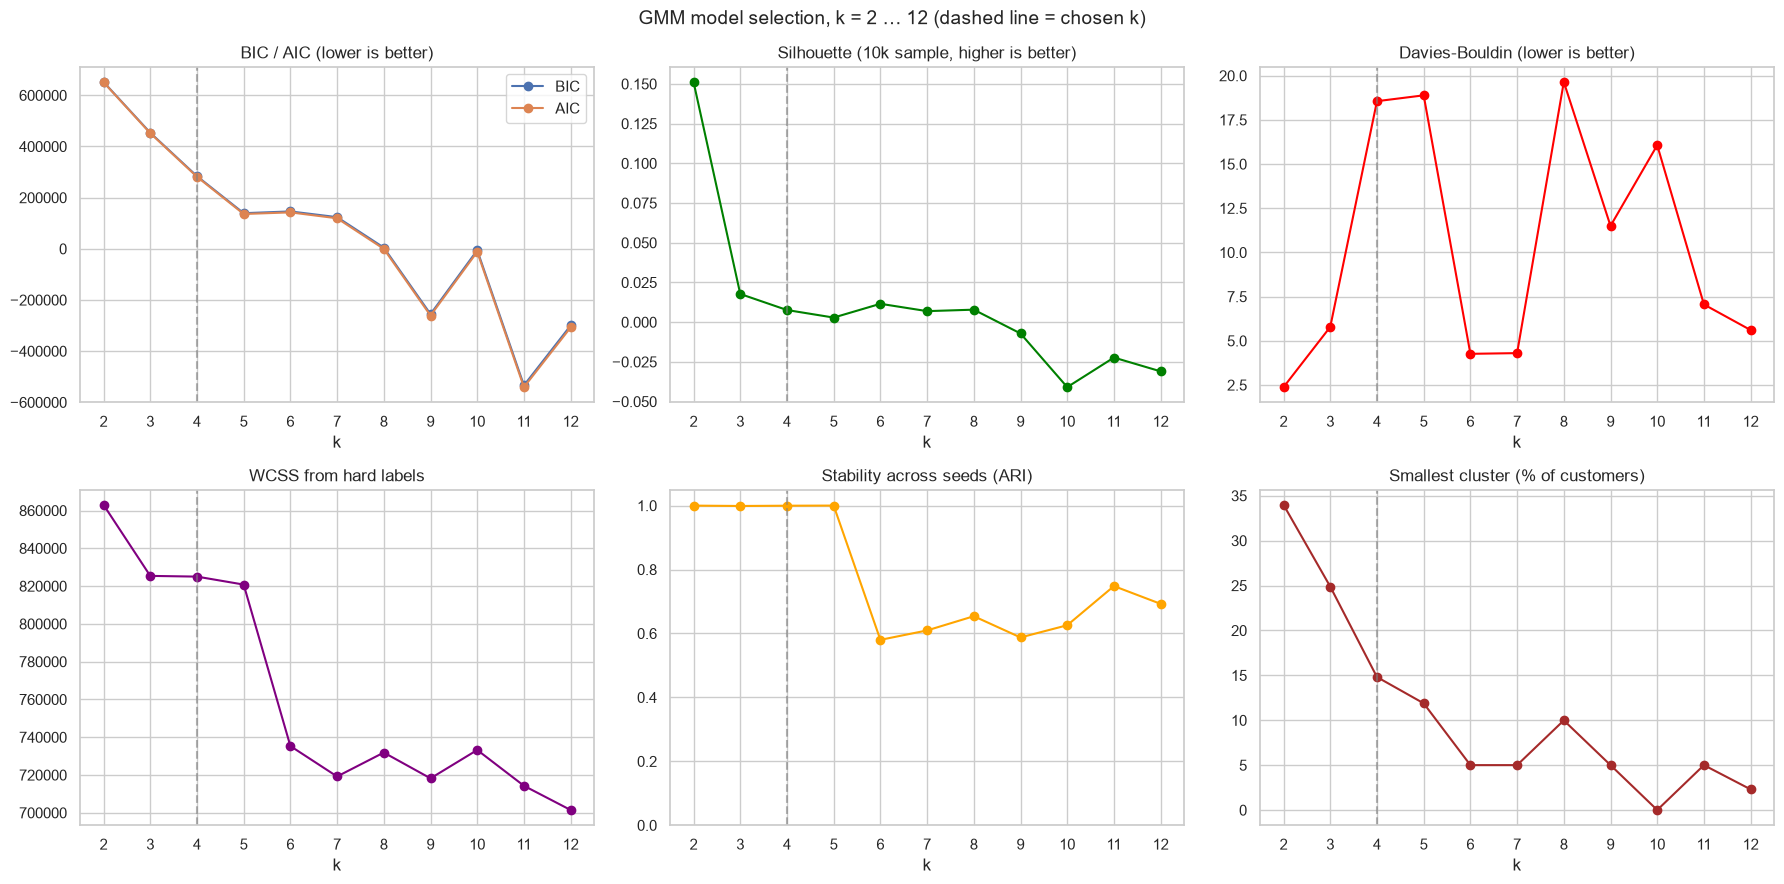

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
results[["BIC", "AIC"]].plot(ax=axes[0, 0], marker="o"); axes[0, 0].set_title("BIC / AIC (lower is better)")
results["Silhouette_10k"].plot(ax=axes[0, 1], marker="o", color="green"); axes[0, 1].set_title("Silhouette (10k sample, higher is better)")
results["DaviesBouldin"].plot(ax=axes[0, 2], marker="o", color="red"); axes[0, 2].set_title("Davies-Bouldin (lower is better)")
results["WCSS"].plot(ax=axes[1, 0], marker="o", color="purple"); axes[1, 0].set_title("WCSS from hard labels")
results["stability_ARI"].plot(ax=axes[1, 1], marker="o", color="orange"); axes[1, 1].set_title("Stability across seeds (ARI)"); axes[1, 1].set_ylim(0, 1.05)
results["min_cluster_%"].plot(ax=axes[1, 2], marker="o", color="brown"); axes[1, 2].set_title("Smallest cluster (% of customers)")
for ax in axes.ravel():
    ax.axvline(4, ls="--", color="grey", alpha=.6); ax.set_xticks(range(2, 13))
plt.suptitle("GMM model selection, k = 2 … 12 (dashed line = chosen k)", fontsize=14)
plt.tight_layout(); plt.show()

### 2.3.2 Model Selection Results

Silhouette and Davies-Bouldin are best at `k=2` (0.151 and 2.38). At `k=4`, these scores are much weaker (about 0.008 and 18.56), so the four groups are not clearly separated.

BIC and AIC are lower for several larger models, but the scores fluctuate sharply after `k=6`. Our data includes discrete and skewed features, which may encourage GMM to fit narrow components to repeated values. We therefore did not select the number of clusters using BIC alone.

In [22]:
for k in [4, 5]:
    g = GaussianMixture(k, covariance_type="full", random_state=0).fit(X)
    L = g.predict(X)
    summary = df.groupby(L)["purchase_frequency"].agg(["mean", "min", "max", "nunique", "size"]).sort_values("mean")
    print(f"k = {k}"); display(summary)

k = 4


,mean,min,max,nunique,size
1,1.000000,1,1,1,14813
2,2.450728,2,3,2,22051
0,8.239012,3,12,4,38270
3,32.014035,12,60,4,24866


k = 5


,mean,min,max,nunique,size
1,1.000000,1,1,1,14813
0,2.451946,2,3,2,22100
2,5.000000,5,5,1,11888
4,9.765569,8,12,2,26976
3,32.545308,12,60,4,24223


### 2.3.3 Choosing the Number of Clusters

We selected **k=4** as a practical way to describe different levels of purchasing activity. At `k=2`, the distance-based evaluation scores are better, but the model mainly divides customers into lower- and higher-activity groups.

Although `k=5` has a lower BIC than `k=4`, the extra group in the table above contains only customers with exactly five purchases. We did not treat this as a separate customer type because it appears to reflect the discrete purchase-frequency values.

The first three seeds gave similar results for `k=4`, but we checked more seeds in the final training step. This choice prioritizes interpretable groups and is not the best result for every metric.

### 2.3.4 Training the Final GMM

We fitted GMM with `n_components=4` and `covariance_type="full"`, so each group can have its own covariance matrix. We used `max_iter=300` and the default covariance regularization (`reg_covar=1e-6`).

We ran the model with ten random seeds (`n_init=1` per run, using the default k-means initialization) and kept the run with the lowest BIC. We then renamed the groups from lowest to highest average purchase frequency to make the profiles easier to read.

In [23]:
# Try different starting points and keep the model with the lowest BIC.
t0 = time.time()
fits = {s: GaussianMixture(n_components=4, covariance_type="full", n_init=1,
                           max_iter=300, random_state=s).fit(X) for s in range(10)}
best_seed = min(fits, key=lambda s: fits[s].bic(X))
gmm = fits[best_seed]
best_labels = gmm.predict(X)
seed_table = pd.DataFrame({
    "BIC": {s: g.bic(X) for s, g in fits.items()},
    "ARI_vs_best": {s: adjusted_rand_score(best_labels, g.predict(X)) for s, g in fits.items()},
    "smallest_cluster_%": {s: np.bincount(g.predict(X)).min() / len(X) * 100 for s, g in fits.items()},
}).rename_axis("seed")
print(f"10 fits took {time.time() - t0:.0f}s | best seed: {best_seed} | converged: {gmm.converged_} | EM iterations: {gmm.n_iter_}")
print(f"Seeds that reach the best solution (ARI > 0.99): {(seed_table['ARI_vs_best'] > 0.99).sum()} / 10")
display(seed_table.round(3))

raw_labels = best_labels
proba = gmm.predict_proba(X)

# Order cluster IDs by average purchase frequency
order = df.groupby(raw_labels)["purchase_frequency"].mean().sort_values().index
remap = {old: new for new, old in enumerate(order)}
df["cluster"] = pd.Series(raw_labels).map(remap).values
proba = proba[:, list(order)]
df["cluster_confidence"] = proba.max(1)

PERSONAS = {0: "One-time Buyers", 1: "Occasional Buyers", 2: "Regular Buyers", 3: "Heavy Users"}
df["persona"] = df["cluster"].map(PERSONAS)
df[["customer_id", "cluster", "persona", "cluster_confidence"]].head()

10 fits took 40s | best seed: 2 | converged: True | EM iterations: 36
Seeds that reach the best solution (ARI > 0.99): 3 / 10


,BIC,ARI_vs_best,smallest_cluster_%
seed,,,
0,283963.820,0.999,14.813
1,283963.825,0.999,14.813
2,283962.733,1.000,14.813
3,396125.906,0.612,20.186
4,448652.971,0.820,16.913
5,384985.841,0.511,12.176
6,403132.740,0.563,19.420
7,395839.912,0.611,21.016
8,396137.245,0.612,20.152


,customer_id,cluster,persona,cluster_confidence
0,C000001,2,Regular Buyers,0.999503
1,C000002,2,Regular Buyers,0.998669
2,C000003,2,Regular Buyers,0.999738
3,C000004,2,Regular Buyers,0.904941
4,C000005,1,Occasional Buyers,0.997363


### Initialization Results

Only 3 of the 10 random seeds reached solutions close to the best one. The other runs had higher BIC scores and different customer assignments. This shows that the result depends on initialization, so we used the lowest-BIC run for the final profiles.

## 2.4 Evaluation Metrics & Visualizations

### 2.4.1 GMM Evaluation


In [24]:
labels = df["cluster"].values
gmm_metrics = {
    "Silhouette (10k sample)": silhouette_score(X_sample, labels[sample_idx]),
    "Davies-Bouldin (full 100k)": davies_bouldin_score(X, labels),
    "WCSS (full 100k)": wcss(X, labels),
    "BIC (full 100k)": gmm.bic(X),
    "AIC (full 100k)": gmm.aic(X),
    "Avg log-likelihood per sample (full)": gmm.score(X),
    "Mean assignment confidence (full)": df["cluster_confidence"].mean(),
}
pd.Series(gmm_metrics).round(4).to_frame("GMM, k=4")

,"GMM, k=4"
Silhouette (10k sample),0.0077
Davies-Bouldin (full 100k),18.5614
WCSS (full 100k),824977.6482
BIC (full 100k),283962.7328
AIC (full 100k),281460.8334
Avg log-likelihood per sample (full),-1.4047
Mean assignment confidence (full),0.9908


### 2.4.2 GMM Visualizations

We visualize the group sizes, PCA projection, and cluster membership confidence.


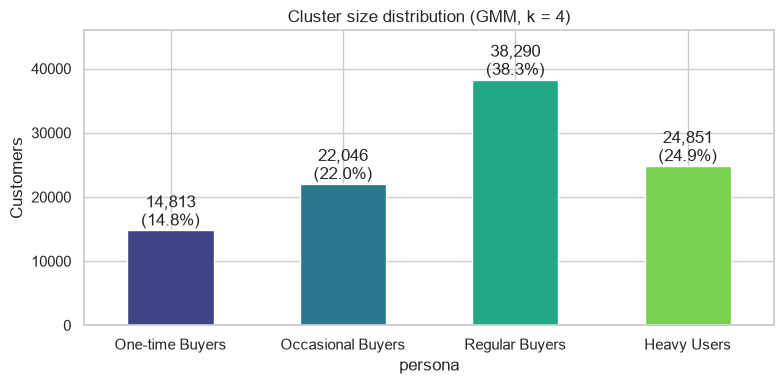

In [25]:
counts = df["persona"].value_counts().reindex(PERSONAS.values())
ax = counts.plot.bar(color=sns.color_palette("viridis", 4), rot=0, figsize=(8, 4))
for i, v in enumerate(counts):
    ax.text(i, v, f"{v:,}\n({v / len(df):.1%})", ha="center", va="bottom")
ax.set_ylabel("Customers"); ax.set_title("Cluster size distribution (GMM, k = 4)")
ax.set_ylim(0, counts.max() * 1.2); plt.tight_layout(); plt.show()

Explained variance ratio: [0.268 0.2  ] | total: 0.468


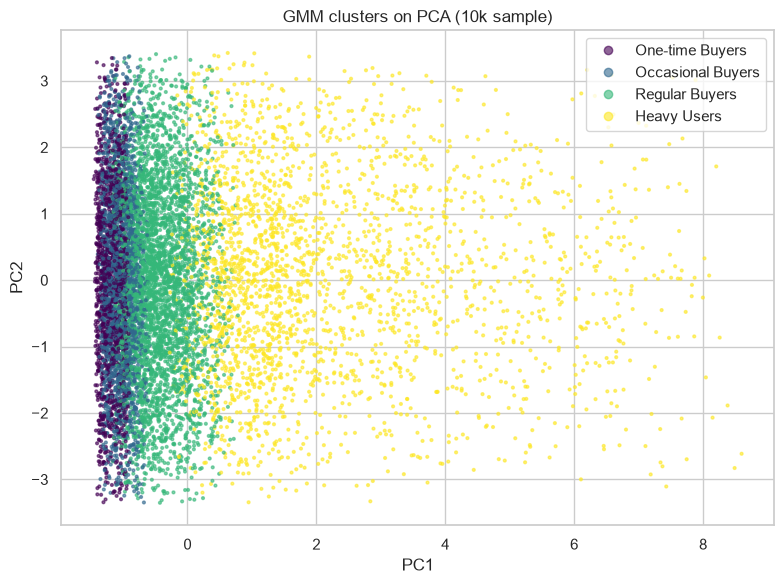

,PC1,PC2
purchase_frequency,0.58,0.00
avg_order_value,0.12,-0.00
total_spent,0.57,0.00
recency_days,-0.00,-0.00
website_visits,0.57,0.00
discount_usage_rate,0.01,0.01
email_open_rate,-0.00,0.52
cart_abandonment_rate,0.00,-0.48
loyalty_score,0.01,-0.00
engagement_score,-0.00,0.71


In [26]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3),
      "| total:", pca.explained_variance_ratio_.sum().round(3))

plot_idx = sample_idx
plt.figure(figsize=(8, 6))
sc = plt.scatter(X_pca[plot_idx, 0], X_pca[plot_idx, 1],
                 c=labels[plot_idx], cmap="viridis", s=4, alpha=0.6)
plt.title("GMM clusters on PCA (10k sample)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(handles=sc.legend_elements()[0], labels=list(PERSONAS.values()), loc="upper right")
plt.tight_layout()
plt.show()

pd.DataFrame(pca.components_.T, index=FEATURES, columns=["PC1", "PC2"]).round(2)

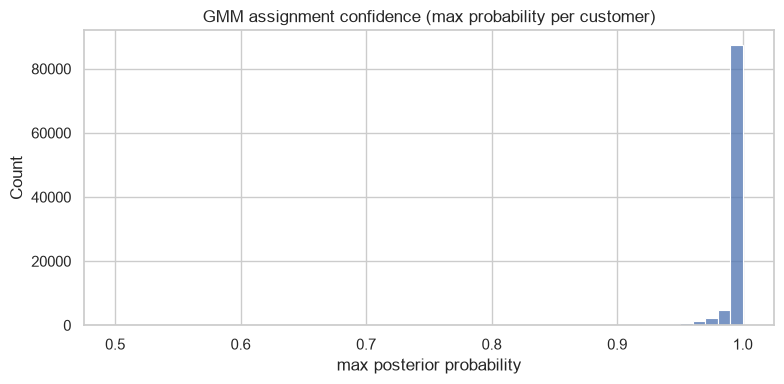

Customers with confidence < 0.8: 1.08%


In [27]:
plt.figure(figsize=(8, 4))
sns.histplot(df["cluster_confidence"], bins=50)
plt.title("GMM assignment confidence (max probability per customer)")
plt.xlabel("max posterior probability"); plt.tight_layout(); plt.show()
print("Customers with confidence < 0.8:", f"{(df['cluster_confidence'] < 0.8).mean():.2%}")


### 2.4.3 Visualization Findings

The first two principal components explain about 47% of the total variance (26.8% and 20.0%), so the PCA plot only shows part of the variation in the data.

The clusters are mainly arranged along PC1, which is related to purchasing activity, including purchase frequency, total spending, and website visits. The groups overlap, especially among the lower-activity segments. PC2 does not clearly separate them.

The Davies-Bouldin score is high (18.56), and the Silhouette Score is close to zero. These results indicate weak distance-based separation, even though GMM assigns high membership probabilities to many customers.


### 2.4.4 Comparison with K-Means

The full comparison of the two algorithms is in Part 3.

## 2.5 Cluster Interpretation & Profiles

We used the original feature values to describe the customer groups. The group names reflect purchasing activity, not churn risk.


In [28]:
KEY = ["purchase_frequency", "avg_order_value", "total_spent", "recency_days", "website_visits",
       "discount_usage_rate", "loyalty_score", "engagement_score"]
profile = df.groupby("persona")[FEATURES].mean().reindex(PERSONAS.values())
profile["size_%"] = df["persona"].value_counts(normalize=True).reindex(PERSONAS.values()) * 100
profile.T.round(2)

persona,One-time Buyers,Occasional Buyers,Regular Buyers,Heavy Users
purchase_frequency,1.00,2.45,8.24,32.03
avg_order_value,209.49,210.08,205.98,215.24
total_spent,215.09,527.54,1714.19,6999.17
recency_days,183.91,182.80,182.37,182.56
website_visits,4.49,11.73,40.74,159.64
discount_usage_rate,0.43,0.43,0.43,0.43
email_open_rate,0.48,0.47,0.47,0.48
cart_abandonment_rate,0.45,0.45,0.45,0.45
loyalty_score,54.77,54.40,54.58,54.77
engagement_score,51.02,51.17,51.17,51.28


In [29]:
# Medians of the key features (less affected by the long tails than the means)
df.groupby("persona")[KEY].median().reindex(PERSONAS.values()).T.round(2)

persona,One-time Buyers,Occasional Buyers,Regular Buyers,Heavy Users
purchase_frequency,1.00,2.00,8.00,20.00
avg_order_value,208.78,209.45,204.97,217.41
total_spent,212.34,500.33,1527.23,5645.53
recency_days,184.00,183.00,182.00,182.00
website_visits,4.00,11.00,36.00,132.00
discount_usage_rate,0.43,0.42,0.42,0.43
loyalty_score,55.00,54.00,55.00,55.00
engagement_score,51.00,51.00,51.00,51.50


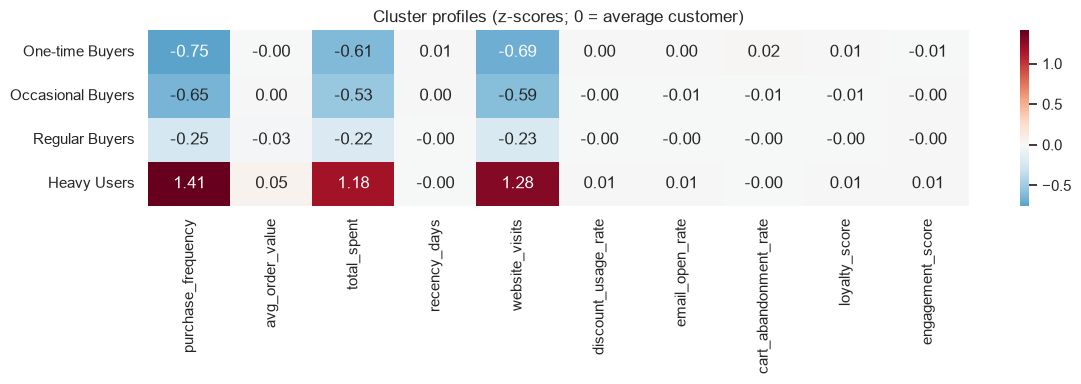

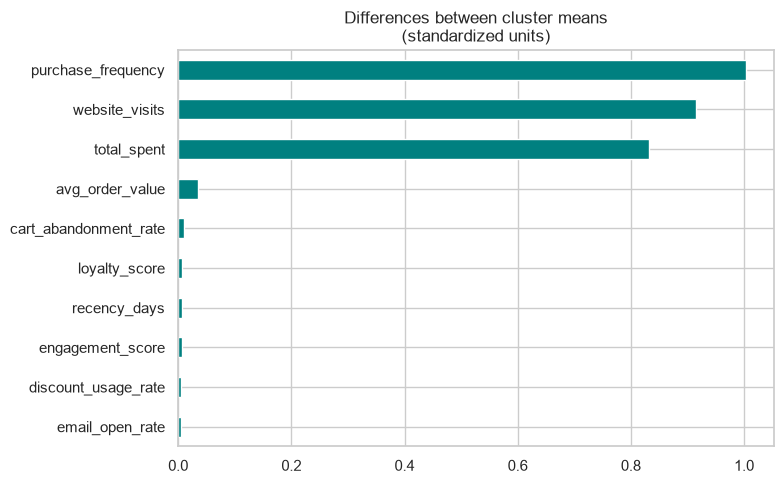

In [30]:
# Feature profile heatmap: cluster mean in standard deviations from the overall mean
z_profile = pd.DataFrame(X, columns=FEATURES).groupby(labels).mean()
z_profile.index = [PERSONAS[i] for i in z_profile.index]
plt.figure(figsize=(12, 4))
sns.heatmap(z_profile, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Cluster profiles (z-scores; 0 = average customer)"); plt.tight_layout(); plt.show()

# Compare differences in cluster means across features
importance = z_profile.std().sort_values(ascending=True)
importance.plot.barh(figsize=(8, 5), color="teal")
plt.title("Differences between cluster means\n(standardized units)")
plt.tight_layout(); plt.show()

In [31]:
# Churn per cluster (churn was NOT used for clustering; we only check it afterwards)
churn_tab = df.groupby("persona").agg(customers=("customer_id", "size"),
                                      churn_rate=("churn_flag", "mean")).reindex(PERSONAS.values())
churn_tab = churn_tab.join(pd.crosstab(df["persona"], df["churn_risk"], normalize="index"))
display(churn_tab.round(3))
print("Overall churn rate:", round(df["churn_flag"].mean(), 3))

,customers,churn_rate,High,Low,Medium
persona,,,,,
One-time Buyers,14813,0.486,0.346,0.378,0.276
Occasional Buyers,22046,0.478,0.343,0.383,0.274
Regular Buyers,38290,0.468,0.328,0.397,0.275
Heavy Users,24851,0.426,0.288,0.438,0.274


Overall churn rate: 0.462


### 2.5.1 Customer Segments
The main differences between the groups are purchase frequency, website visits, and total spending. We named them according to purchasing activity:

| Cluster | Segment | Main characteristics |
|---|---|---|
| 0 | One-time Buyers | Around 15% of customers; one purchase and about 215 in total spending |
| 1 | Occasional Buyers | Around 22%; usually 2–3 purchases and about 530 in spending |
| 2 | Regular Buyers | Around 38%; about 8 purchases and 1,700 in spending |
| 3 | Heavy Users | Around 25%; about 32 purchases and 7,000 in spending |

Average order value is similar across the groups, so spending differences mostly follow purchase frequency. Recency, discount usage, loyalty score, and engagement score are also similar across all four groups. We therefore did not describe any group as more loyal or more engaged.

Churn rates range from about 42.6% to 48.6%. These clusters are not churn predictions; that task belongs to Phase 1.

### 2.5.2 Added Value of GMM

The clusters are mainly related to purchase frequency, so simple rules could produce similar customer groups. We checked whether GMM adds anything beyond such rules by looking at customers with the same purchase count in different clusters, and at customers with lower assignment confidence.

In [32]:
# Find purchase counts that appear in more than one cluster
groups_per_value = df.groupby("purchase_frequency")["persona"].nunique()
shared_values = groups_per_value[groups_per_value > 1].index.tolist()
print("Purchase counts found in more than one cluster:", shared_values)

# Check whether customers with the same purchase count
# can belong to different clusters
boundary = df[df["purchase_frequency"].isin(shared_values)]

display(pd.crosstab(
    boundary["purchase_frequency"],
    boundary["persona"]
))

# Check customers with lower assignment confidence
borderline = df[df["cluster_confidence"] < 0.8]

print("Customers with confidence below 80%:", len(borderline))
print("Percentage:", round(len(borderline) / len(df) * 100, 2), "%")

display(borderline["persona"].value_counts())

Purchase counts found in more than one cluster: [3, 12]


persona,Heavy Users,Occasional Buyers,Regular Buyers
purchase_frequency,,,
3,0,9934,54
12,813,0,11279


Customers with confidence below 80%: 1076
Percentage: 1.08 %


persona
Regular Buyers       555
Heavy Users          345
Occasional Buyers    176
Name: count, dtype: int64


The results show that customers with the same purchase frequency can belong to different clusters. This happened at purchase frequencies of 3 and 12. For example, among customers with 12 purchases, 11,279 were classified as Regular Buyers and 813 as Heavy Users. This shows that purchase frequency alone does not fully determine the cluster assignments.

GMM also provides membership probabilities. We found that 1,076 customers (1.08%) had an assignment confidence below 80%. Most of these customers were Regular Buyers (555), followed by Heavy Users (345) and Occasional Buyers (176).

These probabilities could help the CCO system identify customers whose cluster assignments are less certain.


## 2.6 Integration Strategy

The supervised model from Phase 1 predicts churn risk, while GMM groups customers by purchasing activity. The CCO system could combine these results to suggest retention actions.

For example, One-time Buyers could receive a second-purchase offer, while Occasional Buyers could receive a reminder or recommendation based on their recent purchases. Regular Buyers could receive personalized product suggestions, and Heavy Users could be offered priority support or a reward. Churn predictions from Phase 1 could help decide which customers to prioritize. These are proposed actions, not strategies tested in this experiment.

The notebook exports customer IDs, group labels, and membership probabilities. 
The notebook exports the customer segmentation results as a CSV file. We also saved the trained GMM model and preprocessing pipeline so that new customers can be assigned to the same segments.


In [33]:
os.makedirs("outputs", exist_ok=True)
out = df[["customer_id", "cluster", "persona", "cluster_confidence"]].join(
    pd.DataFrame(proba, columns=[f"p_{PERSONAS[i].replace(' ', '_')}" for i in range(4)]))
out.to_csv("outputs/gmm_customer_segments.csv", index=False)
print("Saved", out.shape, "-> outputs/gmm_customer_segments.csv")
out.head()

Saved (100000, 8) -> outputs/gmm_customer_segments.csv


,customer_id,cluster,persona,cluster_confidence,p_One-time_Buyers,p_Occasional_Buyers,p_Regular_Buyers,p_Heavy_Users
0,C000001,2,Regular Buyers,0.999503,0.0,1.896934e-17,0.999503,0.000497
1,C000002,2,Regular Buyers,0.998669,0.0,1.095634e-106,0.998669,0.001331
2,C000003,2,Regular Buyers,0.999738,0.0,1.159450e-09,0.999738,0.000262
3,C000004,2,Regular Buyers,0.904941,0.0,8.861857e-101,0.904941,0.095059
4,C000005,1,Occasional Buyers,0.997363,0.0,9.973633e-01,0.002593,0.000043



### 2.6.1 Saving and Reusing the GMM Model

We saved the trained GMM model and preprocessing pipeline so that new customers can be assigned to the same segments without retraining the model.

We also saved the feature names and cluster mapping to keep the assignments consistent.


In [34]:
import joblib

# Save everything needed to assign new customers to the same segments
model_bundle = {
    "preprocess": preprocess,   # fitted StandardScaler pipeline
    "gmm": gmm,                 # fitted GMM model
    "order": list(order),       # original GMM cluster IDs, ordered by purchase frequency
    "personas": PERSONAS,       # cluster number -> segment name
    "features": FEATURES,       # input columns in the correct order
}
joblib.dump(model_bundle, "outputs/gmm_model.joblib")
print("Saved -> outputs/gmm_model.joblib")

Saved -> outputs/gmm_model.joblib


In [35]:

# Load the saved model
bundle = joblib.load("outputs/gmm_model.joblib")

def assign_segment(customers):
    X_new = bundle["preprocess"].transform(
        customers[bundle["features"]]
    )

    probabilities = bundle["gmm"].predict_proba(X_new)
    probabilities = probabilities[:, bundle["order"]]

    clusters = probabilities.argmax(axis=1)

    return pd.DataFrame({
        "cluster": clusters,
        "persona": [bundle["personas"][c] for c in clusters],
        "cluster_confidence": probabilities.max(axis=1)
    }, index=customers.index)


# Check that the saved model reproduces the existing assignments
check = assign_segment(df)

print(
    "Same segments as before:",
    (check["cluster"].values == df["cluster"].values).all()
)


Same segments as before: True


In [36]:

# Example of a new customer
new_customer = pd.DataFrame([{
    "purchase_frequency": 15,
    "avg_order_value": 200,
    "total_spent": 3000,
    "recency_days": 30,
    "website_visits": 80,
    "discount_usage_rate": 0.3,
    "email_open_rate": 0.5,
    "cart_abandonment_rate": 0.2,
    "loyalty_score": 70,
    "engagement_score": 60
}])

display(assign_segment(new_customer))


,cluster,persona,cluster_confidence
0,2,Regular Buyers,0.945244



The example customer made 15 purchases and was classified as a Regular Buyer with 94.5% confidence.

Although this is a hypothetical customer, the example shows how the saved GMM model can be used to assign new customers to existing segments. The model considers all 10 numerical features when making the assignment, rather than using purchase frequency alone.


## 2.7 Challenges & Limitations

**Weak cluster separation.** The Silhouette Score for `k=4` is close to zero, and Davies-Bouldin is high (18.56). The groups mainly describe levels of purchasing activity rather than clearly separated customer types.

**Feature distributions.** Some inputs are skewed or discrete, which may not fit Gaussian components well. Correlated purchasing features may also have more influence on the grouping.

**Initialization.** Only 3 of the 10 seeds reached solutions close to the lowest-BIC result, so we kept the best run.

**Feature selection and scaling.** We excluded categorical features, and different feature sets or scaling methods could produce different clusters.

**Limited churn differences.** Churn rates are fairly similar across the four groups. GMM should support segmentation, not replace the Phase 1 churn model.

**Computational cost.** Fitting GMM on 100,000 customers takes time, so we calculated Silhouette using a 10,000-customer sample.

Future work could test transformations for skewed features and evaluate whether the groups help improve retention decisions.

# Part 3: Comparison of K-Means and GMM

## 3.1 Comparison Setup

The two algorithms were set up differently, so their scores cannot be compared directly.

| | K-Means (Part 1) | GMM (Part 2) |
|---|---|---|
| Features | 10 numeric (3 log-transformed) + 5 categorical, one-hot encoded: 30 columns | 10 numeric, standardized: 10 columns |
| Number of clusters | 3 | 4 |
| Cluster assignment | One cluster per customer (hard) | Probability for every cluster (soft) |
| How k was chosen | WCSS, silhouette, Davies-Bouldin, churn spread | BIC/AIC, silhouette, Davies-Bouldin, stability, and interpretability |

To make the comparison fair, we do three things. We score both sets of labels in both feature spaces. We measure how much the two segmentations agree. We check how well each one relates to churn. We also look at practical points such as speed and stability.

## 3.2 Evaluation in a Common Feature Space

We scored both sets of labels in the K-Means feature space and in the GMM feature space. This way both algorithms are judged on the same data.

In [37]:
km_lab = df["kmeans_cluster"].to_numpy()      # K-Means labels (Part 1)
gmm_lab = df["cluster"].to_numpy()            # final GMM labels (Part 2)
X_gmm = X                                     # GMM feature space: 10 standardized numeric features

def internal_scores(space, labels):
    return {"Silhouette (10k sample)": silhouette_score(space[sample_idx], labels[sample_idx]),
            "Davies-Bouldin (lower is better)": davies_bouldin_score(space, labels)}

score_rows = []
for space_name, space in [("K-Means space (30 columns)", X_km), ("GMM space (10 columns)", X_gmm)]:
    for algo, lab in [("K-Means (k = 3)", km_lab), ("GMM (k = 4)", gmm_lab)]:
        score_rows.append({"Feature space": space_name, "Algorithm": algo, **internal_scores(space, lab)})

common_scores = pd.DataFrame(score_rows).set_index(["Feature space", "Algorithm"])
common_scores.round(3)

Silhouette (10k sample)  Davies-Bouldin (lower is better)
Feature space              Algorithm                                                                 
K-Means space (30 columns) K-Means (k = 3)                    0.099                             2.448
                           GMM (k = 4)                        0.037                             4.992
GMM space (10 columns)     K-Means (k = 3)                    0.097                             2.089
                           GMM (k = 4)                        0.008                            18.561

### Reading the table

The K-Means labels score better than the GMM labels on both measures, in both feature spaces. In the K-Means space the silhouette is 0.099 against 0.037, and the Davies-Bouldin Index is 2.45 against 4.99. In the GMM space it is 0.097 against 0.008, and 2.09 against 18.56.

Two cautions apply.

- Silhouette and Davies-Bouldin are distance-based. K-Means directly minimizes distances to cluster centers, so these measures favor it. GMM maximizes likelihood, so BIC and AIC (Part 2) are closer to its own objective.
- All scores are low. Neither algorithm finds well-separated clusters. The PCA plots in Parts 1 and 2 show the same thing: customers form a continuous cloud, and both methods cut it into regions.

We do not compare WCSS across the two algorithms. WCSS always falls when k grows, so a model with k = 4 would look better than one with k = 3 for that reason alone.

## 3.3 Agreement Between the Two Segmentations

Adjusted Rand Index between K-Means and GMM: 0.228


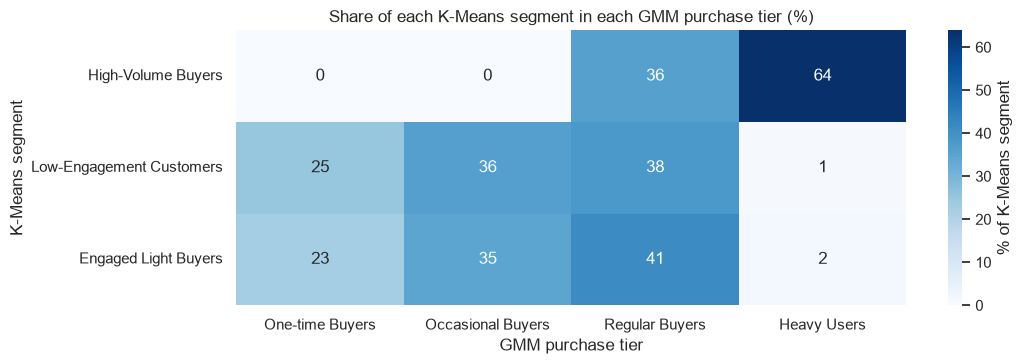

In [38]:
ari_km_gmm = adjusted_rand_score(km_lab, gmm_lab)
print("Adjusted Rand Index between K-Means and GMM:", round(ari_km_gmm, 3))

# Where do the customers of each K-Means segment fall in the GMM purchase tiers? (row %)
overlap = pd.crosstab(df["kmeans_segment"], df["persona"], normalize="index") * 100
overlap = overlap.reindex(index=list(KM_SEGMENTS.values()), columns=list(PERSONAS.values()))

plt.figure(figsize=(11, 3.8))
sns.heatmap(overlap, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of K-Means segment"})
plt.title("Share of each K-Means segment in each GMM purchase tier (%)")
plt.xlabel("GMM purchase tier"); plt.ylabel("K-Means segment")
plt.tight_layout(); plt.show()

### Reading the agreement

The Adjusted Rand Index is only 0.228, so the two segmentations agree weakly. The heatmap shows why.

- **High-Volume Buyers** (K-Means) contain only Regular Buyers (36%) and Heavy Users (64%) from the GMM. Both algorithms recognize the high-purchase customers.
- **Low-Engagement Customers** and **Engaged Light Buyers** (K-Means) are each spread across One-time, Occasional and Regular Buyers (25% / 36% / 38% and 23% / 35% / 41%). They contain almost no Heavy Users (1% and 2%).

So K-Means separates light buyers by **engagement**, which the GMM tiers ignore. The GMM separates customers by **number of purchases** (1, 2–3, about 8, 12 or more), which K-Means no longer does after the log transform. The two algorithms describe different parts of the data, so they complement each other instead of repeating each other.

## 3.4 Business Relevance (Churn)

In [39]:
def churn_summary(col, order_):
    rates = df.groupby(col)["churn_flag"].mean().reindex(order_) * 100
    return {"segments": len(order_), "lowest churn (%)": rates.min(), "highest churn (%)": rates.max(),
            "range (pct points)": rates.max() - rates.min()}

churn_compare = pd.DataFrame({
    "K-Means (k = 3)": churn_summary("kmeans_segment", list(KM_SEGMENTS.values())),
    "GMM (k = 4)": churn_summary("persona", list(PERSONAS.values())),
}).T
display(churn_compare.round(1))

# Churn rate for every combination of K-Means segment and GMM purchase tier
combo_churn = df.pivot_table(index="kmeans_segment", columns="persona", values="churn_flag", aggfunc="mean")
combo_churn = combo_churn.reindex(index=list(KM_SEGMENTS.values()), columns=list(PERSONAS.values())) * 100
combo_n = pd.crosstab(df["kmeans_segment"], df["persona"]).reindex(index=list(KM_SEGMENTS.values()), columns=list(PERSONAS.values()))

print("Churn rate (%) by K-Means segment (rows) and GMM purchase tier (columns):")
display(combo_churn.round(1))
print("Number of customers in each combination:")
display(combo_n)

,segments,lowest churn (%),highest churn (%),range (pct points)
K-Means (k = 3),3.0,40.9,54.1,13.3
GMM (k = 4),4.0,42.6,48.6,6.0


Churn rate (%) by K-Means segment (rows) and GMM purchase tier (columns):


persona,One-time Buyers,Occasional Buyers,Regular Buyers,Heavy Users
kmeans_segment,,,,
High-Volume Buyers,NaN,NaN,46.5,42.6
Low-Engagement Customers,54.4,52.8,55.0,59.8
Engaged Light Buyers,41.9,42.3,39.3,32.9


Number of customers in each combination:


persona,One-time Buyers,Occasional Buyers,Regular Buyers,Heavy Users
kmeans_segment,,,,
High-Volume Buyers,0,0,13657,24139
Low-Engagement Customers,7866,11434,11944,241
Engaged Light Buyers,6947,10612,12689,471


### Reading the churn tables

The K-Means segments are more useful for churn. Their churn rates run from 40.9% to 54.1%, a gap of 13.3 percentage points. The GMM tiers run from 42.6% to 48.6%, a gap of only 6.0 points.

The combined table adds a second finding. Inside each K-Means segment, the churn rate changes little between GMM tiers when the groups are large. Among Low-Engagement Customers it stays between 52.8% and 55.0% for the One-time, Occasional and Regular tiers (each with more than 7,800 customers). Among Engaged Light Buyers it stays between 39.3% and 42.3%. The larger differences appear only in the Heavy Users column, which has few customers in these two segments (241 and 471), so we do not read much into them.

In short, engagement is what separates low-risk from high-risk customers here, and the purchase tier adds little on top of it. Churn was not used to build either segmentation, so this is an independent check.

## 3.5 Practical Considerations

In [40]:
t0 = time.time(); KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10).fit(X_km); t_km = time.time() - t0
t0 = time.time(); GaussianMixture(n_components=4, covariance_type="full", max_iter=300, random_state=best_seed).fit(X_gmm); t_gmm = time.time() - t0
print(f"One final fit: K-Means (n_init=10) {t_km:.1f}s | GMM {t_gmm:.1f}s")
print(f"K-Means search (k = 2 to 8, 10,000-customer sample): {km_search_seconds:.0f}s")
print("K-Means stability across 5 seeds, lowest ARI:", round(min(km_ari), 3))
print("GMM seeds that reach the best solution (ARI > 0.99):", int((seed_table["ARI_vs_best"] > 0.99).sum()), "of 10")

One final fit: K-Means (n_init=10) 0.8s | GMM 4.6s
K-Means search (k = 2 to 8, 10,000-customer sample): 4s
K-Means stability across 5 seeds, lowest ARI: 0.996
GMM seeds that reach the best solution (ARI > 0.99): 3 of 10


### Reading the practical comparison

- **Speed:** both final models fit in a few seconds on 100,000 customers. The model search is the slow part. The K-Means search (k = 2 to 8 on a 10,000-customer sample) was fast. The GMM search (k = 2 to 12 with three seeds on all customers) took several minutes (Section 2.3.1).
- **Stability:** K-Means gives almost the same segments for every seed. GMM is sensitive to its starting point: only 3 of 10 seeds reached the best solution, so we keep the run with the lowest BIC.
- **Interpretability:** a K-Means segment is an average customer profile. A GMM component also has a covariance matrix, which is harder to explain. In return, GMM gives a membership probability for each customer.
- **Reuse:** both models are saved and can assign new customers to a segment (Sections 1.6 and 2.6.1).

## 3.6 Conclusion: Which Algorithm Should We Use?

| Criterion | K-Means (k = 3) | GMM (k = 4) |
|---|---|---|
| Silhouette (own feature space) | 0.099 | 0.008 |
| Davies-Bouldin (own feature space) | 2.45 | 18.56 |
| Churn gap between segments | 13.3 points | 6.0 points |
| Cluster sizes | 31% to 38% | 15% to 38% |
| Stability across seeds | Very high (ARI of 0.996 or higher) | Depends on initialization (3 of 10 seeds reach the best solution) |
| Membership probabilities | No | Yes (mean confidence 0.99) |
| What the segments describe | Purchase volume and engagement | Number of purchases |

**K-Means is our main segmentation.** It has the better separation scores, it is much more stable, and its segments are linked to churn. Its three segments are balanced and easy to explain, and they reflect engagement, which a retention team can act on.

**GMM is our supporting segmentation.** Its four purchase tiers (One-time, Occasional, Regular and Heavy Users) help to personalize offers by purchase level. Its membership probabilities also mark customers whose segment is uncertain (1.08% have a confidence below 80%).

Neither algorithm finds strongly separated clusters. We therefore use both segmentations as context for the Phase 1 churn predictions and not as predictions themselves. Part 4 explains how.

# Part 4: Integration Strategy and Limitations

## 4.1 Integration Strategy

The handbook asks how clustering can improve the system we built in Phase 1. We looked at two options.

**Option 1: use the segments as extra features in the Logistic Regression model.** We tested this in a fair setup. We split the data 80/20 and fitted the scaling and each clustering model on the training data only. Test customers were then assigned to a segment with the trained model, so no test information leaked into the clustering. The baseline is Logistic Regression with the same settings as Phase 1 (C = 0.01).

In [41]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

X_train, X_test, y_train, y_test = train_test_split(
    X_km_raw, y_churn, test_size=0.2, stratify=y_churn, random_state=RANDOM_STATE
)

base_pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])
A_train = base_pre.fit_transform(X_train)
A_test = base_pre.transform(X_test)

def log_transform(data):
    data = data.copy()
    data[skewed_features] = np.log1p(data[skewed_features])
    return data

km_pre_tr = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])
C_train = km_pre_tr.fit_transform(log_transform(X_train))
C_test = km_pre_tr.transform(log_transform(X_test))
km_tr = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10).fit(C_train)
km_seg_train, km_seg_test = km_tr.predict(C_train), km_tr.predict(C_test)

gmm_scaler = StandardScaler().fit(X_train[num_cols])
G_train = gmm_scaler.transform(X_train[num_cols])
G_test = gmm_scaler.transform(X_test[num_cols])
gmm_fits = [GaussianMixture(n_components=4, covariance_type="full", max_iter=300, random_state=s).fit(G_train) for s in range(10)]
gmm_tr = min(gmm_fits, key=lambda m: m.bic(G_train))
gmm_seg_train, gmm_seg_test = gmm_tr.predict(G_train), gmm_tr.predict(G_test)

def one_hot(train_seg, test_seg):
    enc = OneHotEncoder(sparse_output=False).fit(train_seg.reshape(-1, 1))
    return enc.transform(train_seg.reshape(-1, 1)), enc.transform(test_seg.reshape(-1, 1))

km_oh_train, km_oh_test = one_hot(km_seg_train, km_seg_test)
gmm_oh_train, gmm_oh_test = one_hot(gmm_seg_train, gmm_seg_test)

experiments = {
    "Logistic Regression (Phase 1 features)": (A_train, A_test),
    "+ K-Means segment": (np.hstack([A_train, km_oh_train]), np.hstack([A_test, km_oh_test])),
    "+ GMM segment": (np.hstack([A_train, gmm_oh_train]), np.hstack([A_test, gmm_oh_test])),
    "+ both segments": (np.hstack([A_train, km_oh_train, gmm_oh_train]), np.hstack([A_test, km_oh_test, gmm_oh_test])),
}

lr_rows = []
for name, (tr, te) in experiments.items():
    model = LogisticRegression(C=0.01, max_iter=1000).fit(tr, y_train)
    pred = model.predict(te)
    prob = model.predict_proba(te)[:, 1]
    lr_rows.append({"Model": name,
                    "Accuracy": round(accuracy_score(y_test, pred), 4),
                    "F1-score": round(f1_score(y_test, pred), 4),
                    "ROC-AUC": round(roc_auc_score(y_test, prob), 4)})

pd.DataFrame(lr_rows)

,Model,Accuracy,F1-score,ROC-AUC
0,Logistic Regression (Phase 1 features),0.9455,0.9409,0.9904
1,+ K-Means segment,0.9457,0.9412,0.9904
2,+ GMM segment,0.9459,0.9415,0.9904
3,+ both segments,0.9460,0.9415,0.9904


### Result and integration plan

Adding the segments made almost no difference. The F1-score moved from 0.9409 to between 0.9412 and 0.9415, and the ROC-AUC stayed at 0.9904. These changes are too small to count as an improvement. This is expected. Both segmentations are built from features that Logistic Regression already uses, so they add little new information. Our split uses a fixed random seed and may not be identical to the Phase 1 split, but the baseline scores match Phase 1 closely.

**Option 2: use the segments as context for the prediction (our choice).** We keep Logistic Regression as the prediction model and use the segments to explain and personalize its output.

- **Churn risk:** Logistic Regression gives each customer a churn probability and shows the main drivers.
- **Why they are at risk (K-Means):** the K-Means segment shows the customer's engagement level. Low-Engagement Customers churn the most.
- **What to offer (GMM):** the GMM purchase tier shows how much the customer buys, so the offer can match it. The membership probability marks customers whose tier is uncertain.
- **Dashboard:** show the churn probability, both segments and the main drivers for each customer. Executives can filter by segment and compare KPIs.
- **Generative AI briefings:** add the churn probability, the segments and the confidence to the prompt, so the retention advice matches the customer. For example, a customer with a high churn probability who is a Low-Engagement Customer and an Occasional Buyer could receive a re-engagement email together with a second-purchase reminder.

The labels of both algorithms are saved in `Dataset/clustered_data.csv` for these steps. Segments describe broad groups. They do not predict whether an individual customer will churn. These are proposed actions, not strategies tested in this experiment. Any action should be reviewed and monitored.

## 4.2 Challenges & Limitations (whole system)

Part 2 lists the challenges specific to GMM in Section 2.7. The main limitations of the whole clustering work are below.

- **Weak cluster structure.** Silhouette scores are 0.1 or lower for both algorithms, and the WCSS curve has no clear elbow. The customers form a continuous cloud and not clearly separated groups. K-Means with k = 3 and GMM with k = 4 are judgments based on interpretability, not clear optima.
- **The segments describe only some behavior.** They reflect purchase volume and engagement. Recency, loyalty score and the demographic features do not separate them, and recency is the strongest churn signal (r = 0.77 in Part A). The segments therefore explain churn only partly.
- **The comparison is indirect.** The two algorithms use different features and different numbers of clusters. We scored both in both feature spaces and used agreement and churn as extra checks, but a perfectly controlled comparison would use identical inputs.
- **Skewed features needed a transform for K-Means.** We applied log(1 + x) to three features. Without it, K-Means mostly isolated a small high-volume group.
- **Categorical features add noise to K-Means.** They are spread evenly across segments and add 20 one-hot columns to the distance calculation. GMM does not use them.
- **K-Means assumes compact, roughly spherical clusters.** The PCA plot shows the segments touching each other, so customers near a border could belong to either group.
- **Sensitive to initialization (GMM).** Only 3 of 10 seeds reached the best solution (Section 2.7).
- **Little gain for prediction.** Adding the segments to Logistic Regression did not improve it, so the segments are mainly useful for explanation and personalization.
- **Sample used for choosing k in K-Means.** We chose k on a random sample of 10,000 customers for speed. The final model uses all 100,000.
- **The data may be synthetic.** Very regular patterns, such as evenly spread demographics, suggest this, so real customer data could behave differently.

## 4.3 Saving the Combined Results

In [ ]:
output_path = Path(DATA_PATH).parent / "clustered_data.csv"
clustered_out = df.rename(columns={"cluster": "gmm_cluster", "persona": "gmm_persona", "cluster_confidence": "gmm_confidence"})
clustered_out.to_csv(output_path, index=False)

with open("cluster_profiles.txt", "w", encoding="utf-8") as f:
    f.write("K-MEANS SEGMENTS (k = 3)\n")
    f.write(f"Silhouette: {km_silhouette:.3f} | Davies-Bouldin: {km_db:.3f} | WCSS: {km_wcss:,.0f}\n\n")
    f.write("Average feature values per segment:\n" + km_profile.T.to_string() + "\n\n")
    f.write("Customers and churn rate per segment:\n" + km_churn_profile.to_string() + "\n\n\n")
    f.write("GMM SEGMENTS (k = 4)\n")
    f.write(f"Silhouette: {gmm_metrics['Silhouette (10k sample)']:.3f} | Davies-Bouldin: {gmm_metrics['Davies-Bouldin (full 100k)']:.3f}\n\n")
    f.write("Average feature values per segment:\n" + profile.T.to_string() + "\n\n")
    f.write("Customers and churn rate per segment:\n" + churn_tab.round(3).to_string() + "\n")

print("Saved:", output_path, clustered_out.shape)
print("Saved: cluster_profiles.txt, outputs/kmeans_model.joblib, plots in", results_dir)

# Written interpretation of the segments
with open("cluster_profiles.txt", "a", encoding="utf-8") as f:
    f.write("\n\nINTERPRETATION\n\n")
    f.write("K-Means (main segmentation)\n")
    f.write("- High-Volume Buyers (37.8%): buy often and spend the most. Churn rate 44.0%. Protect them with loyalty rewards.\n")
    f.write("- Low-Engagement Customers (31.5%): few emails opened, many abandoned carts. Churn rate 54.1%, the highest. First priority for re-engagement.\n")
    f.write("- Engaged Light Buyers (30.7%): buy little but respond to emails. Churn rate 40.9%, the lowest. Offer recommendations to raise order size.\n\n")
    f.write("GMM (supporting segmentation)\n")
    f.write("- Four purchase tiers: One-time, Occasional, Regular and Heavy Users. Churn rates are 48.6%, 47.8%, 46.8% and 42.6%.\n")
    f.write("- Membership probabilities flag customers whose tier is uncertain (1.08% have confidence below 80%).\n\n")
    f.write("Overall: the overall churn rate is 46.2%. Neither algorithm finds sharply separated groups, so segments are used as context for the Phase 1 churn predictions, not as predictions themselves.\n")

Saved: ..\Dataset\clustered_data.csv (100000, 23)
Saved: cluster_profiles.txt, outputs/kmeans_model.joblib, plots in clustering_results
